<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [2]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

# Final Project: Boston Housing Data Analysis for Upper Management

## Task 1: Familiarize Yourself with the Dataset
In this section, we explore the initial structure, data types, missing values, duplicates, and correlation matrix of the Boston Housing dataset.


In [3]:
# Display the first 5 rows of the dataset
boston_df.head()


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [4]:
# Display the data types of each column
boston_df.dtypes


Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

In [5]:
# Check for missing values in each column
boston_df.isnull().sum()


Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

In [6]:
# Check for duplicate rows
print("Duplicate rows count:", boston_df.duplicated().sum())


Duplicate rows count: 0


In [7]:
# Display the correlation matrix of the dataset
correlation_matrix = boston_df.corr()
correlation_matrix


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


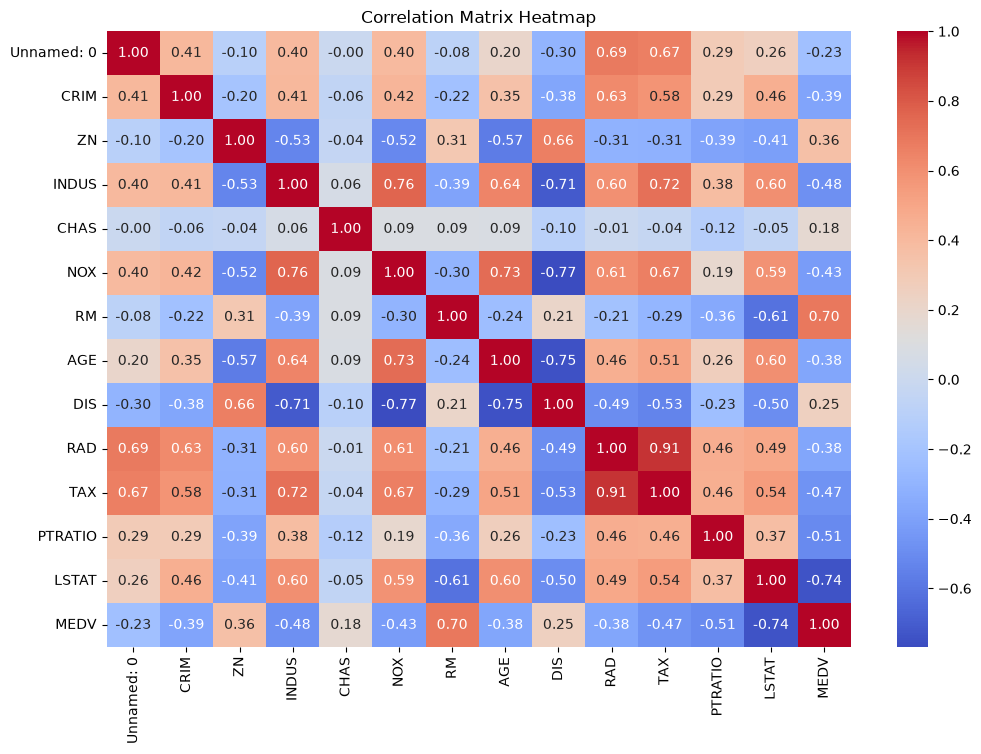

In [8]:
# Visualize correlation matrix heatmap
pyplot.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
pyplot.title("Correlation Matrix Heatmap")
pyplot.show()


## Task 2: Generate Descriptive Statistics and Visualizations
In this section, we compute descriptive statistics and generate required plots with actionable management interpretations.


In [9]:
# Display descriptive statistics of the dataset
boston_df.describe()


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### 1. Boxplot for MEDV (Median value of owner-occupied homes)


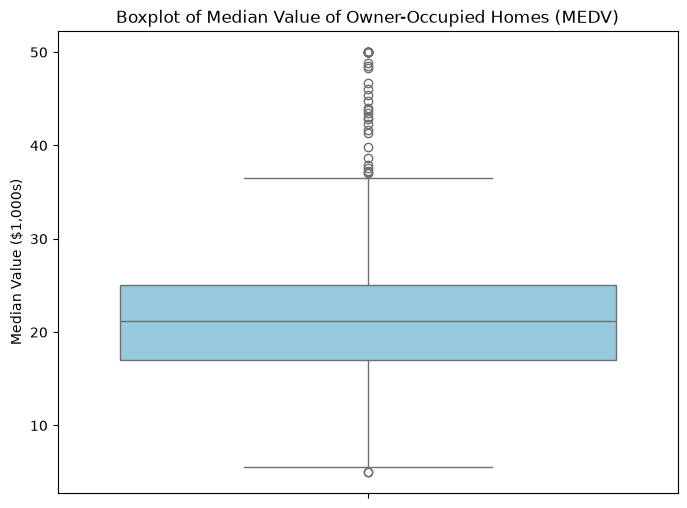

In [10]:
pyplot.figure(figsize=(8, 6))
sns.boxplot(y='MEDV', data=boston_df, color='skyblue')
pyplot.title("Boxplot of Median Value of Owner-Occupied Homes (MEDV)")
pyplot.ylabel("Median Value ($1,000s)")
pyplot.show()


**Interpretation for Management:**
The boxplot for MEDV reveals a median home value of approximately $21,200 with an interquartile range (IQR) roughly between $17,000 and $25,000. Several upper outliers exist above $37,000, including a distinct cluster at $50,000 (reflecting the census top-coded value limit). Overall, the distribution is slightly right-skewed with most homes concentrated below $25,000.


### 2. Bar plot for CHAS (Charles River dummy variable)


C:\Users\Admin\AppData\Local\Temp\ipykernel_12808\2994186179.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='CHAS', data=boston_df, palette='Set2')


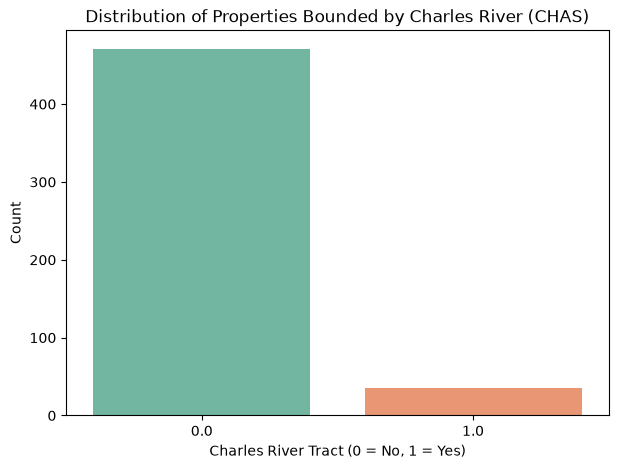

In [11]:
pyplot.figure(figsize=(7, 5))
sns.countplot(x='CHAS', data=boston_df, palette='Set2')
pyplot.title("Distribution of Properties Bounded by Charles River (CHAS)")
pyplot.xlabel("Charles River Tract (0 = No, 1 = Yes)")
pyplot.ylabel("Count")
pyplot.show()


**Interpretation for Management:**
The overwhelming majority of tracts (471 tracts, ~93%) are not bounded by the Charles River (CHAS = 0), while only 35 tracts (~7%) border the river (CHAS = 1). This demonstrates that properties bordering the Charles River are scarce and represent a premium, distinct segment of the housing inventory.


### 3. Boxplot of MEDV versus AGE Groups
Discretize the AGE variable into three groups:
* 35 years and younger
* between 35 and 70 years
* 70 years and older


C:\Users\Admin\AppData\Local\Temp\ipykernel_12808\3382291493.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='age_group', y='MEDV', data=boston_df, order=order, palette='Pastel1')


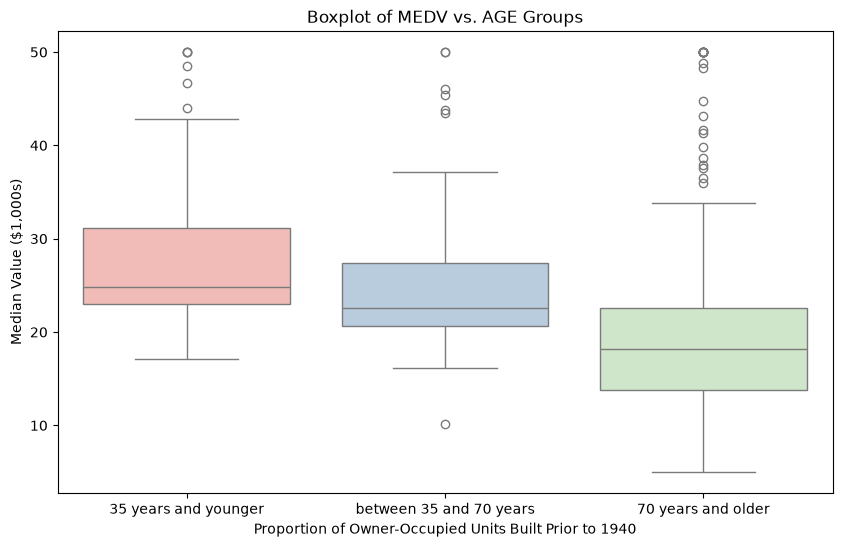

In [12]:
# Discretize AGE into three groups
boston_df.loc[boston_df['AGE'] <= 35, 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[boston_df['AGE'] >= 70, 'age_group'] = '70 years and older'

# Create boxplot
pyplot.figure(figsize=(10, 6))
order = ['35 years and younger', 'between 35 and 70 years', '70 years and older']
sns.boxplot(x='age_group', y='MEDV', data=boston_df, order=order, palette='Pastel1')
pyplot.title("Boxplot of MEDV vs. AGE Groups")
pyplot.xlabel("Proportion of Owner-Occupied Units Built Prior to 1940")
pyplot.ylabel("Median Value ($1,000s)")
pyplot.show()


**Interpretation for Management:**
There is a clear negative relationship between property age and median home value:
* **35 years and younger:** Highest median home values (~$24,000 - $28,000).
* **Between 35 and 70 years:** Intermediate median values (~$21,000).
* **70 years and older:** Lowest median values (~$17,000 - $18,000).
Neighborhoods dominated by older pre-1940 structures suffer lower property valuations, suggesting depreciation or higher maintenance costs.


### 4. Scatter Plot: NOX (Nitric Oxide Concentrations) vs. INDUS (Non-Retail Business Acres)


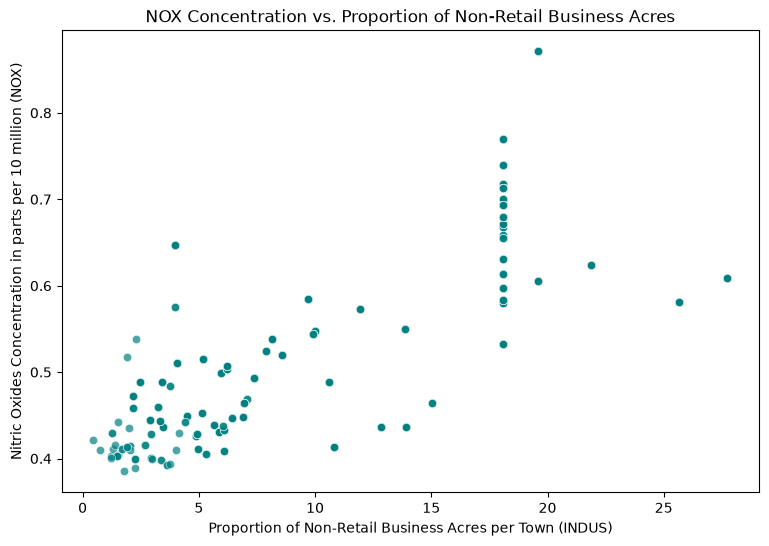

In [13]:
pyplot.figure(figsize=(9, 6))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df, color='teal', alpha=0.7)
pyplot.title("NOX Concentration vs. Proportion of Non-Retail Business Acres")
pyplot.xlabel("Proportion of Non-Retail Business Acres per Town (INDUS)")
pyplot.ylabel("Nitric Oxides Concentration in parts per 10 million (NOX)")
pyplot.show()


**Interpretation for Management:**
The scatter plot demonstrates a strong positive linear relationship between the proportion of non-retail industrial business acres and nitric oxide concentration. Areas with higher commercial/industrial activity experience markedly elevated air pollution levels, especially clustering around 18% industrial zoning.


### 5. Histogram for PTRATIO (Pupil-Teacher Ratio)


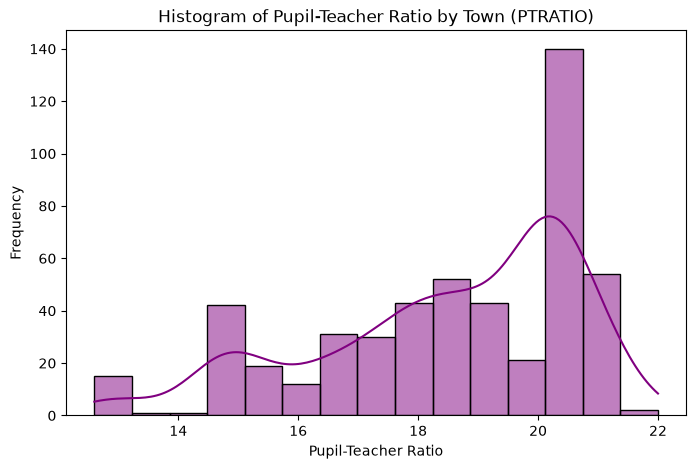

In [14]:
pyplot.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], bins=15, kde=True, color='purple')
pyplot.title("Histogram of Pupil-Teacher Ratio by Town (PTRATIO)")
pyplot.xlabel("Pupil-Teacher Ratio")
pyplot.ylabel("Frequency")
pyplot.show()


**Interpretation for Management:**
The histogram shows that the pupil-teacher ratio is negatively skewed, with the highest concentration occurring at approximately 20.2 pupils per teacher. Towns with ratios above 20 represent high classroom density, which can impact local school quality perceptions and home pricing.


## Task 3: Apply Statistical Tests
In this section, we formulate formal hypotheses at the alpha = 0.05 significance level, execute statistical tests, and report management conclusions.


### 1. Levene's Test: Equality of Variances for MEDV by Charles River
* **Null Hypothesis (H0):** The variance of MEDV for homes bounded by the Charles River is equal to the variance of MEDV for homes not bounded by the Charles River (sigma1^2 = sigma2^2).
* **Alternative Hypothesis (H1):** The variances of MEDV between the two groups are not equal (sigma1^2 != sigma2^2).


In [15]:
medv_c0 = boston_df[boston_df['CHAS'] == 0]['MEDV']
medv_c1 = boston_df[boston_df['CHAS'] == 1]['MEDV']

levene_stat, levene_p = scipy.stats.levene(medv_c0, medv_c1, center='mean')
print(f"Levene's Test: Statistic = {levene_stat:.4f}, p-value = {levene_p:.4e}")


Levene's Test: Statistic = 8.7519, p-value = 3.2381e-03


**Conclusion:**
Since the p-value (0.0032 < 0.05), we reject the null hypothesis. The variances of home values for properties bounded by the river vs. not bounded by the river are significantly unequal. Therefore, Welch's t-test (equal_var=False) is appropriate.


### 2. T-Test: Difference in MEDV between homes bounded vs. not bounded by Charles River
* **Null Hypothesis (H0):** There is no significant difference in median home values (MEDV) between houses bounded by the Charles River and those not bounded (mu1 = mu2).
* **Alternative Hypothesis (H1):** There is a significant difference in median home values between houses bounded by the Charles River and those not bounded (mu1 != mu2).


In [16]:
ttest_stat, ttest_p = scipy.stats.ttest_ind(medv_c0, medv_c1, equal_var=False)
print(f"Two-sample T-test (Welch's): Statistic = {ttest_stat:.4f}, p-value = {ttest_p:.4e}")


Two-sample T-test (Welch's): Statistic = -3.1133, p-value = 3.5672e-03


**Conclusion for Management:**
Since the p-value (0.00357 < 0.05), we reject the null hypothesis. There is a statistically significant difference in median house values based on Charles River frontage. Homes bounded by the Charles River have significantly higher median values than homes not bounded by the river.


### 3. ANOVA: Comparing MEDV among the Three AGE Groups
* **Null Hypothesis (H0):** The mean MEDV is equal across all three age groups (mu_young = mu_middle = mu_old).
* **Alternative Hypothesis (H1):** At least one age group has a significantly different mean MEDV.


In [17]:
group_young = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
group_middle = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
group_old = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

f_stat, anova_p = scipy.stats.f_oneway(group_young, group_middle, group_old)
print(f"ANOVA Test: F-statistic = {f_stat:.4f}, p-value = {anova_p:.4e}")


ANOVA Test: F-statistic = 36.4076, p-value = 1.7105e-15


**Conclusion for Management:**
Since the p-value (1.71 x 10^-15 < 0.05), we reject the null hypothesis. There is a statistically significant difference in median home values among the three age groups. Management can conclude that property age is a major driver of market valuation.


### 4. Pearson Correlation: NOX and INDUS
* **Null Hypothesis (H0):** There is no linear correlation between nitric oxide concentrations (NOX) and non-retail business acreage (INDUS) (r = 0).
* **Alternative Hypothesis (H1):** There is a significant linear correlation between NOX and INDUS (r != 0).


In [18]:
corr_coeff, corr_p = scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print(f"Pearson Correlation Coefficient = {corr_coeff:.4f}, p-value = {corr_p:.4e}")


Pearson Correlation Coefficient = 0.7637, p-value = 7.9134e-98


**Conclusion for Management:**
With a Pearson correlation coefficient r = 0.7637 and p-value < 0.001, we reject the null hypothesis. There is a strong, statistically significant positive linear relationship between industrial non-retail business presence and nitric oxide air pollution.


### 5. Simple Linear Regression: Impact of DIS (Distance to Employment Centres) on MEDV
* **Null Hypothesis (H0):** Weighted distance to employment centres (DIS) has no significant linear impact on median home value (beta1 = 0).
* **Alternative Hypothesis (H1):** Weighted distance to employment centres has a significant linear impact on median home value (beta1 != 0).


In [19]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

linear_model = sm.OLS(y, X).fit()
print(linear_model.summary())


                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        16:12:44   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

**Conclusion for Management:**
* **Coefficient Interpretation:** The regression coefficient for DIS is +1.0916 (p < 0.001). This indicates that for each additional unit of weighted distance to the five Boston employment centers, the median value of an owner-occupied home increases by approximately **$1,092** ($1.0916 x $1,000).
* **Statistical Significance:** The p-value for DIS is 1.21 x 10^-8 (< 0.05), which confirms that distance is a statistically significant predictor of MEDV.
* **Model Fit (R-squared):** R^2 = 0.062, meaning that distance to employment centres explains approximately 6.2% of the total variance in median home values across Boston.
